# 04 - Evaluation and comparison
Loads every finished run from `outputs/runs/` (notebook 03) and answers the questions that decide the paper:

1. **Which variant is best** - table with accuracy, macro-F1, calibration (ECE), error-detection AUROC, referral accuracy, parameters, training time.
2. **Are the differences real or noise?** - paired tests on the *same* test scans: McNemar test and paired bootstrap intervals for the difference to the baseline (accuracy, macro-F1, AUROC).
3. **Does uncertainty help?** - referral curves and reliability diagrams side by side.
4. **Where does the best model fail?** - confusions and the most confident mistakes, with images.
5. **Is the model looking at the right place?** - Grad-CAM, plus a sanity check that the maps really depend on the trained weights.

Sections 1-5 need only numpy and matplotlib; Grad-CAM (section 6) needs PyTorch and the checkpoint.
Run it after at least the baseline run exists; it uses whatever runs are there.

## 1. Settings and load the runs

In [2]:
import re, csv, json, math, collections
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ---------------- settings ----------------
OUT_ROOT = Path("C:/Users/User/Desktop/retinaldataset/OCT_clean")   # dataset (for showing images)
RUNS_DIR = Path("outputs") / "runs"                                   # written by notebook 03
OUT_DIR = Path("outputs") / "comparison"
BASELINE = "cnn_softmax"        # variant every other variant is compared with
FOCUS = None                    # run for error analysis and Grad-CAM, e.g. "ms_evidential_s42"; None = best macro-F1
N_BOOT = 2000                   # bootstrap resamples for the paired comparisons
RUN_GRADCAM = True              # section 6 (needs PyTorch)
CAM_STAGE = 1                   # 0 = stage 2 (28x28), 1 = stage 3 (14x14), 2 = stage 4 (7x7)
# -------------------------------------------

OUT_DIR.mkdir(parents=True, exist_ok=True)
LABEL = {"cnn_softmax": "CNN + softmax (baseline)", "cnn_evidential": "CNN + evidential",
         "ms_softmax": "Multi-scale transformer + softmax", "ms_evidential": "MS-OCTFormer (full)"}
COLOR = {"cnn_softmax": "tab:gray", "cnn_evidential": "tab:orange", "ms_softmax": "tab:blue", "ms_evidential": "tab:red"}
ORDER = list(LABEL)

runs = {}
for d in sorted(RUNS_DIR.glob("*_s*")):
    m = re.match(r"^(cnn|ms)_(softmax|evidential)_s(\d+)$", d.name)
    if m and (d / "metrics.json").exists() and (d / "test_outputs.npz").exists():
        o = np.load(d / "test_outputs.npz")
        runs[d.name] = dict(dir=d, variant=f"{m[1]}_{m[2]}", seed=int(m[3]), metrics=json.load(open(d / "metrics.json")),
                            y=o["y"], pred=o["pred"], unc=o["unc"], probs=o["probs"],
                            paths=o["paths"] if "paths" in o.files else None)
if not runs:
    raise FileNotFoundError(f"No finished runs in {RUNS_DIR}. Run notebook 03 first.")

VARIANTS = [v for v in ORDER if any(r["variant"] == v for r in runs.values())]
first = {v: min((r for r in runs.values() if r["variant"] == v), key=lambda r: r["seed"]) for v in VARIANTS}
CLASSES = list(next(iter(runs.values()))["metrics"]["test"]["per_class"])
K = len(CLASSES)

same_test = all(np.array_equal(r["y"], next(iter(runs.values()))["y"]) for r in runs.values())
print(f"Found {len(runs)} runs:", ", ".join(runs))
print("Variants:", ", ".join(VARIANTS), "| test scans:", len(next(iter(runs.values()))["y"]))
print("All runs use the same test set:", same_test)
if BASELINE not in VARIANTS:
    print(f"NOTE: baseline '{BASELINE}' has no run yet - paired comparisons will be skipped.")

Found 1 runs: cnn_softmax_s42
Variants: cnn_softmax | test scans: 7734
All runs use the same test set: True


## 2. Results table
One row per variant. With several seeds the entries are mean +/- std over seeds; with one seed the 95% bootstrap interval over test scans is shown.

In [3]:
def mean_std(vals):
    vals = [v for v in vals if v is not None]
    if not vals:
        return None, None
    return float(np.mean(vals)), (float(np.std(vals)) if len(vals) > 1 else None)

def fmt(m, s=None, nd=4, scale=1.0):
    if m is None:
        return "n/a"
    return f"{m * scale:.{nd}f}" + (f" +/- {s * scale:.{nd}f}" if s is not None else "")

COLS = [("acc", "Acc (%)", 2, 100.0), ("macro_f1", "Macro-F1", 4, 1.0), ("ece", "ECE", 4, 1.0), ("auroc", "AUROC (err)", 3, 1.0),
        ("acc_at_90", "Acc@90% cov (%)", 2, 100.0), ("acc_at_80", "Acc@80% cov (%)", 2, 100.0), ("errors", "Errors", 1, 1.0)]
rows = []
for v in VARIANTS:
    rs = [r for r in runs.values() if r["variant"] == v]
    row = {"Variant": LABEL[v], "Seeds": ",".join(str(r["seed"]) for r in sorted(rs, key=lambda r: r["seed"]))}
    for key, title, nd, sc in COLS:
        row[title] = fmt(*mean_std([r["metrics"]["test"].get(key) for r in rs]), nd=nd, scale=sc)
    if len(rs) == 1:
        t = rs[0]["metrics"]["test"]
        row["Acc 95% CI (%)"] = f"[{t['acc_ci95'][0] * 100:.2f}, {t['acc_ci95'][1] * 100:.2f}]"
        row["F1 95% CI"] = f"[{t['f1_ci95'][0]:.4f}, {t['f1_ci95'][1]:.4f}]"
    row["Params (M)"] = fmt(rs[0]["metrics"]["cfg"].get("params_m"), nd=1)
    row["Train (min)"] = fmt(*mean_std([r["metrics"].get("train_minutes") for r in rs]), nd=0)
    rows.append(row)

headers = list(dict.fromkeys(h for r in rows for h in r))
for r in rows:
    for h in headers:
        r.setdefault(h, "")
widths = [max(len(h), *(len(r[h]) for r in rows)) for h in headers]
line = lambda cells_: "  ".join(c.ljust(w) for c, w in zip(cells_, widths))
print(line(headers)); print(line(["-" * w for w in widths]))
for r in rows:
    print(line([r[h] for h in headers]))

with open(OUT_DIR / "comparison.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=headers); w.writeheader(); w.writerows(rows)
md_lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)] + ["| " + " | ".join(r[h] for h in headers) + " |" for r in rows]
(OUT_DIR / "comparison.md").write_text("\n".join(md_lines), encoding="utf-8")
print("\nSaved comparison.csv / comparison.md in", OUT_DIR)

Variant                   Seeds  Acc (%)  Macro-F1  ECE     AUROC (err)  Acc@90% cov (%)  Acc@80% cov (%)  Errors  Acc 95% CI (%)  F1 95% CI         Params (M)  Train (min)
------------------------  -----  -------  --------  ------  -----------  ---------------  ---------------  ------  --------------  ----------------  ----------  -----------
CNN + softmax (baseline)  42     93.69    0.9207    0.0511  0.831        96.98            97.88            488.0   [93.17, 94.19]  [0.9140, 0.9273]  27.8        76         

Saved comparison.csv / comparison.md in outputs\comparison


## 3. Are the differences real? (paired tests against the baseline)
Every model is scored on the same test scans, so the comparison is *paired*:
- **McNemar test** on the scans where exactly one of the two models is right.
- **Paired bootstrap** (resampling test scans): 95% interval of the *difference* (variant minus baseline) in accuracy, macro-F1 and error-detection AUROC. If the interval contains 0, there is no clear difference.
With several seeds the lowest-seed run of each variant is used here.

In [4]:
def confusion(y, p, k):
    return np.bincount(y * k + p, minlength=k * k).reshape(k, k)

def prf(cm):
    tp = np.diag(cm).astype(float)
    prec = tp / np.maximum(cm.sum(0), 1)
    rec = tp / np.maximum(cm.sum(1), 1)
    return prec, rec, 2 * prec * rec / np.maximum(prec + rec, 1e-12)

def auroc(pos, neg):
    v = np.concatenate([pos, neg])
    _, inv, cnt = np.unique(v, return_inverse=True, return_counts=True)
    r = (np.cumsum(cnt) - (cnt - 1) / 2.0)[inv]
    n1, n0 = len(pos), len(neg)
    return float((r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def acc_at_coverage(y, pred, unc, cov):
    order = np.argsort(unc, kind="stable")
    keep = order[:max(1, int(round(cov * len(y))))]
    return float((y[keep] == pred[keep]).mean())

def mcnemar_exact(a_ok, b_ok):
    b = int((a_ok & ~b_ok).sum())          # only A right
    c = int((~a_ok & b_ok).sum())          # only B right
    n = b + c
    if n == 0:
        return 1.0, b, c
    p = 2 * sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n
    return min(1.0, p), b, c

def paired_bootstrap(y, pa, pb, ua, ub, k, n_boot, seed=0):
    rng = np.random.default_rng(seed)
    n = len(y)
    d_acc, d_f1, d_auc = [], [], []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yy, a, b = y[idx], pa[idx], pb[idx]
        d_acc.append((a == yy).mean() - (b == yy).mean())
        d_f1.append(prf(confusion(yy, a, k))[2].mean() - prf(confusion(yy, b, k))[2].mean())
        wa, wb = a != yy, b != yy
        if wa.any() and (~wa).any() and wb.any() and (~wb).any():
            d_auc.append(auroc(ua[idx][wa], ua[idx][~wa]) - auroc(ub[idx][wb], ub[idx][~wb]))
    ci = lambda v: tuple(float(x) for x in np.percentile(v, [2.5, 97.5])) if len(v) > 50 else (float("nan"), float("nan"))
    return dict(acc=ci(d_acc), f1=ci(d_f1), auroc=ci(d_auc))

def verdict(ci):
    lo, hi = ci
    if math.isnan(lo):
        return "n/a"
    return "better" if lo > 0 else ("WORSE" if hi < 0 else "no clear difference")

COMPARE = {}
if BASELINE in VARIANTS:
    A = first[BASELINE]
    print(f"Differences = variant minus {LABEL[BASELINE]} (seed {A['seed']}), {len(A['y']):,} test scans, {N_BOOT} bootstrap resamples\n")
    for v in VARIANTS:
        if v == BASELINE:
            continue
        B = first[v]
        p, only_b, only_a = mcnemar_exact(B["pred"] == B["y"], A["pred"] == A["y"])
        bs = paired_bootstrap(A["y"], B["pred"], A["pred"], B["unc"], A["unc"], K, N_BOOT)
        d_acc = ((B["pred"] == B["y"]).mean() - (A["pred"] == A["y"]).mean()) * 100
        COMPARE[v] = dict(mcnemar_p=p, only_variant_right=only_b, only_baseline_right=only_a, d_acc_pp=float(d_acc), **bs)
        print(f"{LABEL[v]}")
        print(f"   accuracy  {d_acc:+.2f} pp  [{bs['acc'][0] * 100:+.2f}, {bs['acc'][1] * 100:+.2f}]  -> {verdict(bs['acc'])}   "
              f"(McNemar p = {p:.3g}; only variant right: {only_b}, only baseline right: {only_a})")
        print(f"   macro-F1  [{bs['f1'][0]:+.4f}, {bs['f1'][1]:+.4f}]  -> {verdict(bs['f1'])}")
        print(f"   AUROC     [{bs['auroc'][0]:+.3f}, {bs['auroc'][1]:+.3f}]  -> {verdict(bs['auroc'])}\n")
    json.dump(COMPARE, open(OUT_DIR / "paired_tests.json", "w"), indent=2)
else:
    print("Baseline run missing - skipped.")

Differences = variant minus CNN + softmax (baseline) (seed 42), 7,734 test scans, 2000 bootstrap resamples



## 4. Plots: referral, training, calibration, per-class

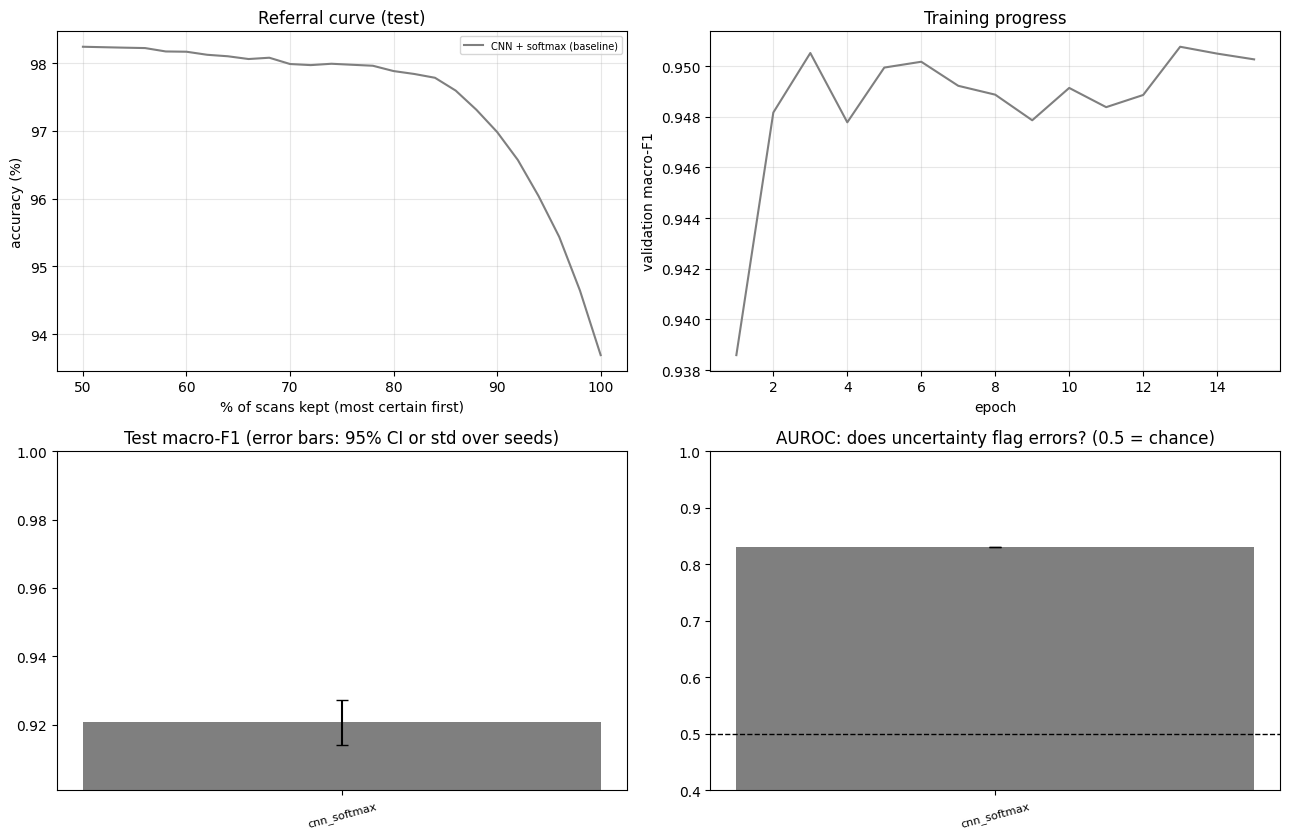

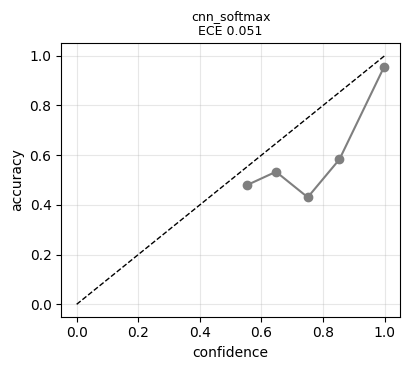

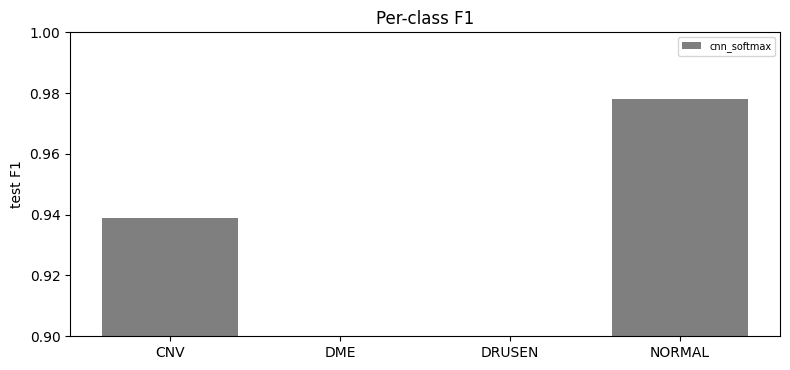

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(13, 8.5))

cov = np.linspace(0.5, 1.0, 26)
for v in VARIANTS:
    r = first[v]
    axs[0, 0].plot(cov * 100, [acc_at_coverage(r["y"], r["pred"], r["unc"], c) * 100 for c in cov], color=COLOR[v], label=LABEL[v])
axs[0, 0].set_xlabel("% of scans kept (most certain first)"); axs[0, 0].set_ylabel("accuracy (%)")
axs[0, 0].set_title("Referral curve (test)"); axs[0, 0].grid(alpha=0.3); axs[0, 0].legend(fontsize=7)

for v in VARIANTS:
    h = json.load(open(first[v]["dir"] / "history.json"))
    axs[0, 1].plot(range(1, len(h["val_f1"]) + 1), h["val_f1"], color=COLOR[v], label=LABEL[v])
axs[0, 1].set_xlabel("epoch"); axs[0, 1].set_ylabel("validation macro-F1"); axs[0, 1].set_title("Training progress"); axs[0, 1].grid(alpha=0.3)

x = np.arange(len(VARIANTS))
f1 = [mean_std([r["metrics"]["test"]["macro_f1"] for r in runs.values() if r["variant"] == v]) for v in VARIANTS]
err = []
for v, (m, s) in zip(VARIANTS, f1):
    rs = [r for r in runs.values() if r["variant"] == v]
    if s is not None:
        err.append([s, s])
    else:
        lo, hi = rs[0]["metrics"]["test"]["f1_ci95"]
        err.append([m - lo, hi - m])
axs[1, 0].bar(x, [m for m, _ in f1], yerr=np.array(err).T, color=[COLOR[v] for v in VARIANTS], capsize=4)
lo_lim = min(m for m, _ in f1) - 0.02
axs[1, 0].set_ylim(max(0, lo_lim), 1.0)
axs[1, 0].set_xticks(x); axs[1, 0].set_xticklabels(VARIANTS, rotation=15, fontsize=8); axs[1, 0].set_title("Test macro-F1 (error bars: 95% CI or std over seeds)")

au = [mean_std([r["metrics"]["test"].get("auroc") for r in runs.values() if r["variant"] == v]) for v in VARIANTS]
axs[1, 1].bar(x, [m if m is not None else 0 for m, _ in au], yerr=[s if s is not None else 0 for _, s in au], color=[COLOR[v] for v in VARIANTS], capsize=4)
axs[1, 1].axhline(0.5, color="k", ls="--", lw=1); axs[1, 1].set_ylim(0.4, 1.0)
axs[1, 1].set_xticks(x); axs[1, 1].set_xticklabels(VARIANTS, rotation=15, fontsize=8); axs[1, 1].set_title("AUROC: does uncertainty flag errors? (0.5 = chance)")
plt.tight_layout(); plt.savefig(OUT_DIR / "comparison_plots.png", dpi=150); plt.show()

# reliability diagrams
fig, axs = plt.subplots(1, len(VARIANTS), figsize=(4.2 * len(VARIANTS), 3.8), squeeze=False)
for ax, v in zip(axs[0], VARIANTS):
    r = first[v]
    conf, cor = r["probs"].max(1), (r["pred"] == r["y"]).astype(float)
    edges = np.linspace(0, 1, 11)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 5:
            xs.append(conf[m].mean()); ys.append(cor[m].mean())
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.plot(xs, ys, "o-", color=COLOR[v])
    ax.set_title(f"{v}\nECE {r['metrics']['test']['ece']:.3f}", fontsize=9); ax.set_xlabel("confidence"); ax.grid(alpha=0.3)
axs[0, 0].set_ylabel("accuracy")
plt.tight_layout(); plt.savefig(OUT_DIR / "reliability.png", dpi=150); plt.show()

# per-class F1
fig, ax = plt.subplots(figsize=(8, 3.8))
wd = 0.8 / len(VARIANTS)
for k, v in enumerate(VARIANTS):
    pc = first[v]["metrics"]["test"]["per_class"]
    ax.bar(np.arange(K) + (k - (len(VARIANTS) - 1) / 2) * wd, [pc[c]["f1"] for c in CLASSES], wd, color=COLOR[v], label=v)
ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES); ax.set_ylabel("test F1"); ax.set_ylim(0.9, 1.0); ax.legend(fontsize=7); ax.set_title("Per-class F1")
plt.tight_layout(); plt.savefig(OUT_DIR / "per_class_f1.png", dpi=150); plt.show()

## 5. Error analysis of the focus run
Which classes get confused, and are the mistakes *confident*? (A confident mistake is one the uncertainty score fails to flag.)

Focus run: cnn_softmax_s42 | test accuracy 93.69% | 488 errors out of 7,734

Most common confusions (true -> predicted):
   CNV     -> DME      194  (40% of errors)
   CNV     -> DRUSEN   109  (22% of errors)
   DRUSEN  -> CNV       36  (7% of errors)
   DME     -> CNV       35  (7% of errors)
   DRUSEN  -> NORMAL    26  (5% of errors)
   NORMAL  -> DRUSEN    26  (5% of errors)

60 of 488 errors (12%) are as certain as a typical correct scan (uncertainty <= 0.000) - these are the mistakes the uncertainty score cannot catch.


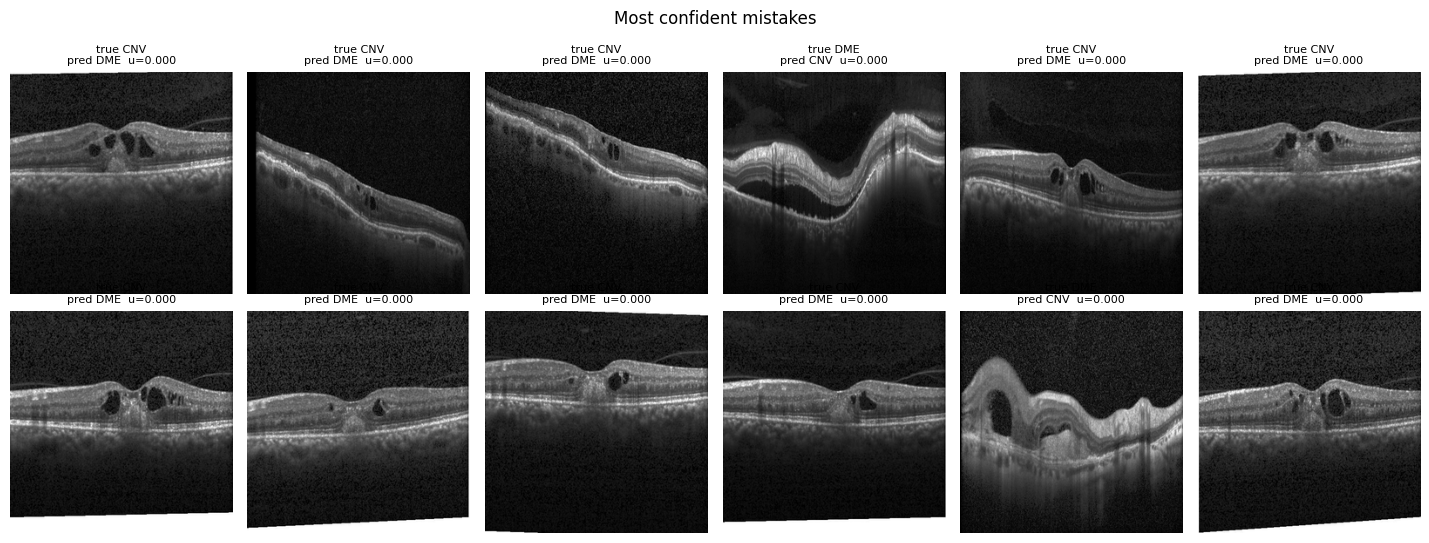

In [6]:
FOCUS_NAME = FOCUS or max(runs, key=lambda n: runs[n]["metrics"]["test"]["macro_f1"])
F_RUN = runs[FOCUS_NAME]
y, pred, unc = F_RUN["y"], F_RUN["pred"], F_RUN["unc"]
wrong = np.where(pred != y)[0]
print(f"Focus run: {FOCUS_NAME} | test accuracy {np.mean(pred == y) * 100:.2f}% | {len(wrong)} errors out of {len(y):,}")

conf_pairs = collections.Counter((CLASSES[y[i]], CLASSES[pred[i]]) for i in wrong)
print("\nMost common confusions (true -> predicted):")
for (t, p), n in conf_pairs.most_common(6):
    print(f"   {t:7s} -> {p:7s} {n:4d}  ({n / len(wrong) * 100:.0f}% of errors)")

med_correct = float(np.median(unc[pred == y]))
n_conf_wrong = int((unc[wrong] <= med_correct).sum()) if len(wrong) else 0
print(f"\n{n_conf_wrong} of {len(wrong)} errors ({n_conf_wrong / max(len(wrong), 1) * 100:.0f}%) are as certain as a typical correct scan "
      f"(uncertainty <= {med_correct:.3f}) - these are the mistakes the uncertainty score cannot catch.")

def resolve(p):
    p = Path(str(p))
    return p if p.exists() else OUT_ROOT.joinpath(*p.parts[-3:])

if F_RUN["paths"] is not None and len(wrong):
    show = wrong[np.argsort(unc[wrong], kind="stable")][:12]          # most confident mistakes first
    cols = 6
    fig, axs = plt.subplots(math.ceil(len(show) / cols), cols, figsize=(2.4 * cols, 2.7 * math.ceil(len(show) / cols)), squeeze=False)
    for ax in axs.ravel():
        ax.axis("off")
    for ax, i in zip(axs.ravel(), show):
        ax.imshow(Image.open(resolve(F_RUN["paths"][i])).convert("L"), cmap="gray")
        ax.set_title(f"true {CLASSES[y[i]]}\npred {CLASSES[pred[i]]}  u={unc[i]:.3f}", fontsize=8)
    plt.suptitle("Most confident mistakes", y=1.0); plt.tight_layout()
    plt.savefig(OUT_DIR / "confident_mistakes.png", dpi=150); plt.show()

## 6. Grad-CAM and a sanity check
Grad-CAM highlights the image regions that push the prediction towards the predicted class (computed on the stage chosen by `CAM_STAGE`).
**These are saliency maps, not lesion segmentations.** The sanity check (Adebayo et al., 2018) re-computes the maps after randomising the classifier head, and then the whole network:
if the maps barely change, they do not reflect what the model learned and should not be used as evidence.

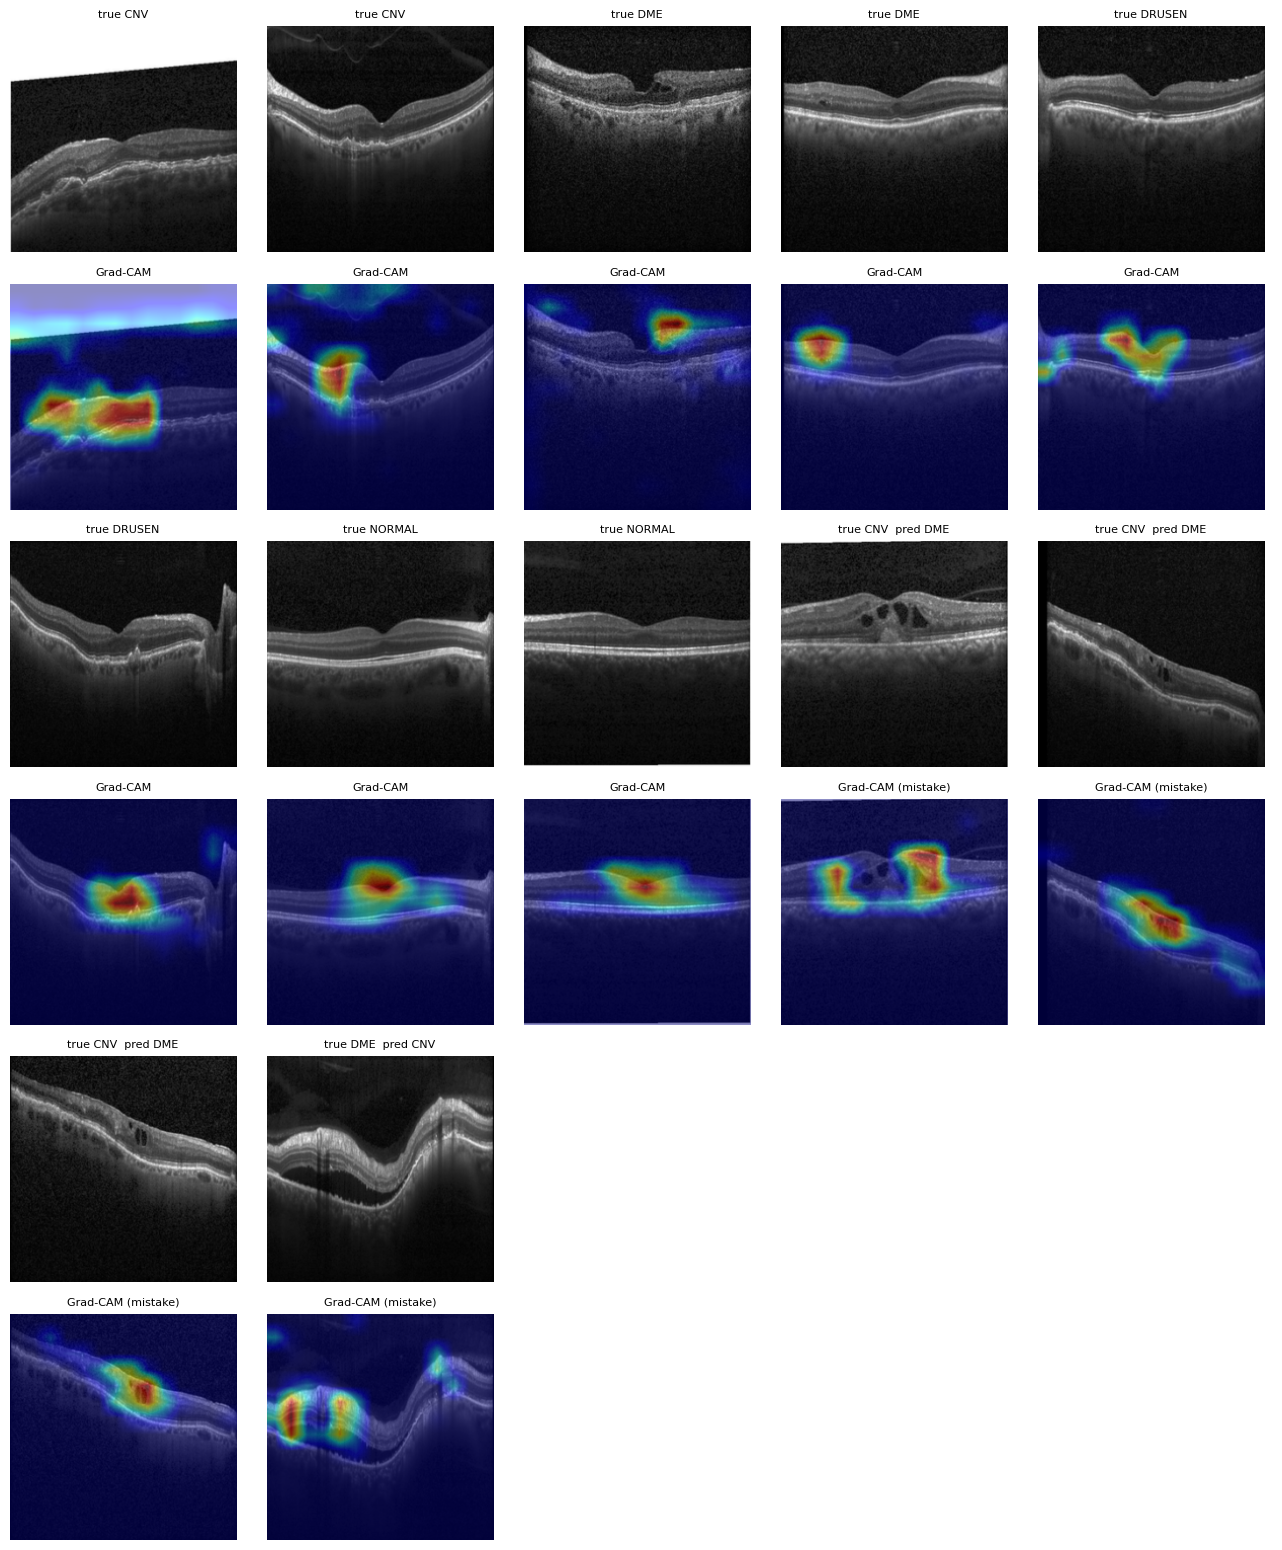

Grad-CAM sanity check on 40 scans (correlation with the trained model's maps; 1 = identical):
   classifier head re-initialised : -0.09
   whole network re-initialised   : +0.20
Both should be clearly below 1 (ideally near 0). If they stay high, the maps do not reflect what was learned.


In [7]:
if not RUN_GRADCAM:
    print("RUN_GRADCAM = False - skipped.")
elif not (F_RUN["dir"] / "best.pt").exists() or F_RUN["paths"] is None:
    print("Checkpoint or image paths missing for", FOCUS_NAME, "- skipped.")
else:
    import copy
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torchvision import transforms
    from torchvision.models import convnext_tiny

    class OCTNet(nn.Module):          # identical to notebook 03 (plus an optional feature output)
        def __init__(self, model, num_classes, dim=256, depth=2, heads=4, dropout=0.1):
            super().__init__()
            self.multiscale = model == "ms"
            self.features = convnext_tiny(weights=None).features
            if self.multiscale:
                self.proj = nn.ModuleList([nn.Sequential(nn.Conv2d(c, dim, 1), nn.AdaptiveAvgPool2d(7)) for c in (192, 384, 768)])
                self.cls = nn.Parameter(torch.zeros(1, 1, dim))
                self.pos = nn.Parameter(torch.zeros(1, 3 * 49 + 1, dim))
                self.tok_norm = nn.LayerNorm(dim)
                layer = nn.TransformerEncoderLayer(dim, heads, dim_feedforward=dim * 2, dropout=dropout,
                                                   activation="gelu", batch_first=True, norm_first=True)
                self.encoder = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
                self.out_norm = nn.LayerNorm(dim)
                self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(dim, num_classes))
            else:
                self.pool_norm = nn.LayerNorm(768)
                self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(768, num_classes))

        def forward(self, x, return_feats=False):
            f = self.features
            x = f[2](f[1](f[0](x)))
            f2 = f[3](x)
            f3 = f[5](f[4](f2))
            f4 = f[7](f[6](f3))
            if not self.multiscale:
                logits = self.head(self.pool_norm(f4.mean((2, 3))))
            else:
                toks = [p(t).flatten(2).transpose(1, 2) for p, t in zip(self.proj, (f2, f3, f4))]
                t = self.tok_norm(torch.cat(toks, dim=1))
                t = torch.cat([self.cls.expand(t.size(0), -1, -1), t], dim=1) + self.pos
                logits = self.head(self.out_norm(self.encoder(t))[:, 0])
            return (logits, (f2, f3, f4)) if return_feats else logits

    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    cfg = F_RUN["metrics"]["cfg"]
    ck = torch.load(F_RUN["dir"] / "best.pt", map_location=dev, weights_only=False)
    net = OCTNet(cfg["model"], K, cfg.get("dim", 256), cfg.get("depth", 2), cfg.get("heads", 4)).to(dev)
    net.load_state_dict(ck["model"])
    net.eval()

    PIPE_FILE = OUT_ROOT / "pipeline.json"
    PIPE = json.load(open(PIPE_FILE)) if PIPE_FILE.exists() else {}
    IMG, MEAN, STD = PIPE.get("net_input_size", 224), PIPE.get("mean", [0.485, 0.456, 0.406]), PIPE.get("std", [0.229, 0.224, 0.225])
    tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    mean_t, std_t = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)

    def load_batch(idx):
        return torch.stack([tf(Image.open(resolve(F_RUN["paths"][i])).convert("RGB")) for i in idx]).to(dev)

    def grad_cam(model, x, stage):
        model.eval()
        with torch.enable_grad():
            logits, feats = model(x, return_feats=True)
            fmap = feats[stage]
            pred_ = logits.argmax(1)
            grads, = torch.autograd.grad(logits.gather(1, pred_[:, None]).sum(), fmap)
        w = grads.mean((2, 3), keepdim=True)
        cam = F.relu((w * fmap).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        flat = cam.flatten(1)
        mn, mx = flat.min(1)[0].view(-1, 1, 1), flat.max(1)[0].view(-1, 1, 1)
        return ((cam - mn) / (mx - mn + 1e-8)).detach().cpu().numpy(), pred_.detach().cpu().numpy()

    rng = np.random.default_rng(0)
    picks = []
    for c in range(K):
        ok = np.where((y == c) & (pred == y))[0]
        if len(ok):
            picks += list(rng.choice(ok, size=min(2, len(ok)), replace=False))
    picks_err = list(wrong[np.argsort(unc[wrong], kind="stable")][:4]) if len(wrong) else []
    idx = picks + picks_err
    x = load_batch(idx)
    cams, cam_pred = grad_cam(net, x, CAM_STAGE)

    cols = 5
    n_rows = math.ceil(len(idx) / cols)
    fig, axs = plt.subplots(n_rows * 2, cols, figsize=(2.6 * cols, 5.2 * n_rows), squeeze=False)
    for ax in axs.ravel():
        ax.axis("off")
    for k, i in enumerate(idx):
        r_, c_ = divmod(k, cols)
        img = (x[k].cpu() * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
        axs[2 * r_, c_].imshow(img)
        axs[2 * r_, c_].set_title(f"true {CLASSES[y[i]]}" + ("" if pred[i] == y[i] else f"  pred {CLASSES[pred[i]]}"), fontsize=8)
        axs[2 * r_ + 1, c_].imshow(img); axs[2 * r_ + 1, c_].imshow(cams[k], cmap="jet", alpha=0.45)
        axs[2 * r_ + 1, c_].set_title("Grad-CAM" + (" (mistake)" if pred[i] != y[i] else ""), fontsize=8)
    plt.tight_layout(); plt.savefig(OUT_DIR / "gradcam.png", dpi=150); plt.show()

    # sanity check: do the maps depend on the learned weights?
    idx_s = np.linspace(0, len(y) - 1, 40).astype(int)
    xs_ = load_batch(idx_s)
    base_cam, _ = grad_cam(net, xs_, CAM_STAGE)

    def reset_linear(module):
        for m in module.modules():
            if isinstance(m, nn.Linear):
                m.reset_parameters()

    head_rand = copy.deepcopy(net)
    reset_linear(head_rand.head)
    torch.manual_seed(0)
    all_rand = OCTNet(cfg["model"], K, cfg.get("dim", 256), cfg.get("depth", 2), cfg.get("heads", 4)).to(dev)

    def mean_corr(model):
        cam2, _ = grad_cam(model, xs_, CAM_STAGE)
        cs = [np.corrcoef(a.ravel(), b.ravel())[0, 1] for a, b in zip(base_cam, cam2)]
        return float(np.nanmean(cs))

    print(f"Grad-CAM sanity check on {len(idx_s)} scans (correlation with the trained model's maps; 1 = identical):")
    print(f"   classifier head re-initialised : {mean_corr(head_rand):+.2f}")
    print(f"   whole network re-initialised   : {mean_corr(all_rand):+.2f}")
    print("Both should be clearly below 1 (ideally near 0). If they stay high, the maps do not reflect what was learned.")

## 7. Summary

In [ ]:
best = max(VARIANTS, key=lambda v: np.mean([r["metrics"]["test"]["macro_f1"] for r in runs.values() if r["variant"] == v]))
print(f"Best variant by test macro-F1: {LABEL[best]}\n")
if COMPARE:
    for v, c in COMPARE.items():
        acc_v, f1_v, au_v = verdict(c["acc"]), verdict(c["f1"]), verdict(c["auroc"])
        print(f"{LABEL[v]} vs baseline: accuracy {c['d_acc_pp']:+.2f} pp ({acc_v}), macro-F1 {f1_v}, error-detection AUROC {au_v}")
    print()
    print("How to read this:")
    print(" - 'no clear difference' = within noise on this test set; a simpler model that ties is the better result.")
    print(" - A fancier variant is only worth reporting as an improvement where the interval excludes 0.")
    print(" - Evidential vs softmax is judged on AUROC / ECE, not accuracy.")
print("\nFiles saved in", OUT_DIR.resolve())

## What to do next
- If differences are "no clear difference", the honest options are: repeat with 3 seeds, or make the contribution the **leakage-free benchmark plus uncertainty study** rather than a new architecture.
- Run the winning variants with `SEED = 43, 44` in notebook 03 and re-run this notebook; tables then show mean +/- std.
- Test the best model on an **external OCT dataset** without retraining (the strongest evidence for generalisation).
- Use `comparison.md`, `comparison_plots.png`, `reliability.png` and `gradcam.png` directly in the paper.